# 1. Librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modelos individuales
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import ValidationCurveDisplay, cross_val_predict

# Modelos extra para ensemble
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import VotingClassifier
from sklearn.base import clone
import ast

# Variables de inicio
import utils.constantes as cte
from utils import modelado as mod

%matplotlib inline

np.random.seed(cte.semilla)

# 2. Train - Test

Datos provenientes de EDA, depurados pero con registros nulos aún, con partición estratificada 80% train, 20% test.

In [2]:
# Misma partición del grupo.
X_train, X_test, y_train, y_test = mod.cargar_datos()

print("Train:", X_train.shape)
print("Proporción de clases:",y_train.value_counts(normalize=True).sort_index().round(2).to_dict())

Train: (1803, 30)
Proporción de clases: {0: 0.5, 1: 0.3, 2: 0.2}


In [3]:
def curva_validacion(busqueda, parametro, valores, titulo):
    """Representa train y validación con media ± desviación, modificando un hiperparámetro."""

    ValidationCurveDisplay.from_estimator(
        busqueda.best_estimator_, X_train,y_train,
        param_name=parametro,
        param_range=valores,
        cv=mod.validador,
        scoring=mod.metrica,
        std_display_style="fill_between",
        n_jobs=-1
    )

    plt.title(titulo)
    plt.ylabel("F1 macro")
    plt.show()

# 3. Balanceo

Enfoque de clases separables:
- Se escoge LDA porque permite separar las medias y controlar la desviación estándar de los datos solapados, vistos en las campanas de Gauss de las 3 clases en EDA. Además asume que los datos son asume que cada clase sigue una distribución normal y que todas comparten la misma matriz de covarianzas, por lo que sus fronteras son lineales; que es lo que arroja la matriz de correlación en EDA.
- Se escoge SVM porque permite separar las clases con distintos kernel, desde lineales a polinómicos, con mayor flexibilidad de LDA aunque sin su ajuste.

In [4]:
rejilla_lda = [
    #Solver minimos cuadrados, con covarianza regularizada según el ruido de las variables 
    {"modelo__solver": ["lsqr"],
    "modelo__shrinkage": [None, "auto", 0.1, 0.5, 0.9],},
    #Solver con descomposición de autovalores, con covarianza regularizada según el ruido
    {"modelo__solver": ["eigen"],
    "modelo__shrinkage": [None, "auto", 0.1, 0.5, 0.9],},]

busquedas_lda, tablas_balanceo_lda = {}, []

# LDA no admite class_weight, probamos sin balanceo, SMOTENC y los dos métodos de undersampling
for balanceo in [None, "smotenc", "tomek", "enn"]:
    busqueda = mod.crear_busqueda(mod.crear_pipeline(LinearDiscriminantAnalysis(),balanceo=balanceo), rejilla_lda)
    busquedas_lda[balanceo] = busqueda.fit(X_train,y_train)
    tablas_balanceo_lda.append(mod.tabla_resultados(busqueda,f"lda | {balanceo}"))

balanceo_resultados_lda = pd.concat(tablas_balanceo_lda)
mod.guardar_preprocesamientos(busquedas_lda, "lda")
display(balanceo_resultados_lda[["f1_macro_val","f1_macro_val_std","recall_alto_val","recall_alto_val_std","precision_alto_val","diferencia_train_val"]].round(3)
)

print("\nMejores hiperparámetros:\n")

for modelo, params in balanceo_resultados_lda["mejores_parametros"].items():
    print(f"{modelo}:")
    print(params)
    print()

,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,diferencia_train_val
modelo,,,,,,
lda | None,0.660,0.038,0.681,0.059,0.698,0.017
lda | smotenc,0.636,0.028,0.759,0.052,0.611,0.021
lda | tomek,0.647,0.040,0.717,0.069,0.675,0.019
lda | enn,0.567,0.034,0.823,0.055,0.571,0.017



Mejores hiperparámetros:

lda | None:
{'modelo__shrinkage': 0.1, 'modelo__solver': 'lsqr'}

lda | smotenc:
{'modelo__shrinkage': 0.5, 'modelo__solver': 'lsqr'}

lda | tomek:
{'modelo__shrinkage': 'auto', 'modelo__solver': 'lsqr'}

lda | enn:
{'modelo__shrinkage': None, 'modelo__solver': 'lsqr'}



In [5]:
rejilla_svm = [
    # Kernel lineal: Frontera plana
    {"modelo__kernel": ["linear"],
    "modelo__C": [0.1, 1, 10, 100],},
    # Kernel RBF: Frontera curva
    {"modelo__kernel": ["rbf"],
    "modelo__C": [0.1, 1, 10, 100],
    "modelo__gamma": ["scale", "auto", 0.01, 0.1],},
    # Kernel polinómico: Frontera adaptada a polinomio
    {"modelo__kernel": ["poly"],
    "modelo__C": [0.1, 1, 10],
    "modelo__degree": [2, 3],
    "modelo__gamma": ["scale", "auto"],},
    # Kernel sigmoide: Frontera adaptada a sigmoide
    {"modelo__kernel": ["sigmoid"],
    "modelo__C": [0.1, 1, 10],
    "modelo__gamma": ["scale", "auto"],},]

busquedas_svm, tablas_balanceo_svm = {}, []

# SVM admite class_weight, así que probamos todas las estrategias

for balanceo in [None, "class_weight", "smotenc", "tomek", "enn"]:

    busqueda = mod.crear_busqueda(mod.crear_pipeline(SVC(),balanceo=balanceo),rejilla_svm)
    busquedas_svm[balanceo] = busqueda.fit(X_train,y_train)
    tablas_balanceo_svm.append(mod.tabla_resultados(busqueda,f"svm | {balanceo}"))

balanceo_resultados_svm = pd.concat(tablas_balanceo_svm)
mod.guardar_preprocesamientos(busquedas_svm, "svm")
display(balanceo_resultados_svm[["f1_macro_val","f1_macro_val_std","recall_alto_val","recall_alto_val_std","precision_alto_val","diferencia_train_val"        ]].round(3))
for modelo, params in balanceo_resultados_svm["mejores_parametros"].items():
    print(f"{modelo}:")
    print(params)
    print()

,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,diferencia_train_val
modelo,,,,,,
svm | None,0.649,0.029,0.676,0.041,0.694,0.026
svm | class_weight,0.648,0.018,0.728,0.045,0.644,0.185
svm | smotenc,0.636,0.022,0.726,0.054,0.636,0.116
svm | tomek,0.643,0.024,0.698,0.051,0.658,0.092
svm | enn,0.556,0.034,0.809,0.064,0.563,0.041


svm | None:
{'modelo__C': 0.1, 'modelo__kernel': 'linear'}

svm | class_weight:
{'modelo__C': 1, 'modelo__gamma': 'scale', 'modelo__kernel': 'rbf'}

svm | smotenc:
{'modelo__C': 1, 'modelo__gamma': 'auto', 'modelo__kernel': 'rbf'}

svm | tomek:
{'modelo__C': 10, 'modelo__gamma': 0.01, 'modelo__kernel': 'rbf'}

svm | enn:
{'modelo__C': 100, 'modelo__kernel': 'linear'}



## 3.1 Visualización de clases en 2 PCA con aplicación de balanceos

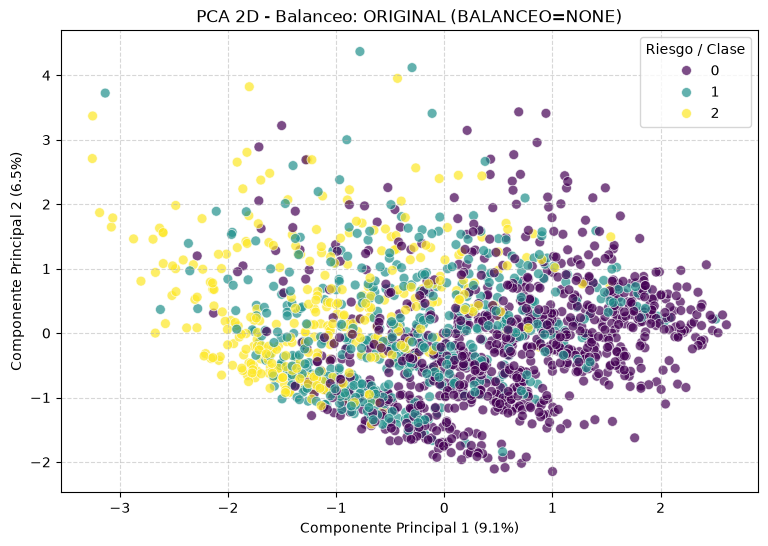

[Original (Balanceo=None)] Muestras: 1803 | Varianza explicada acumulada (PC1 + PC2): 15.52%



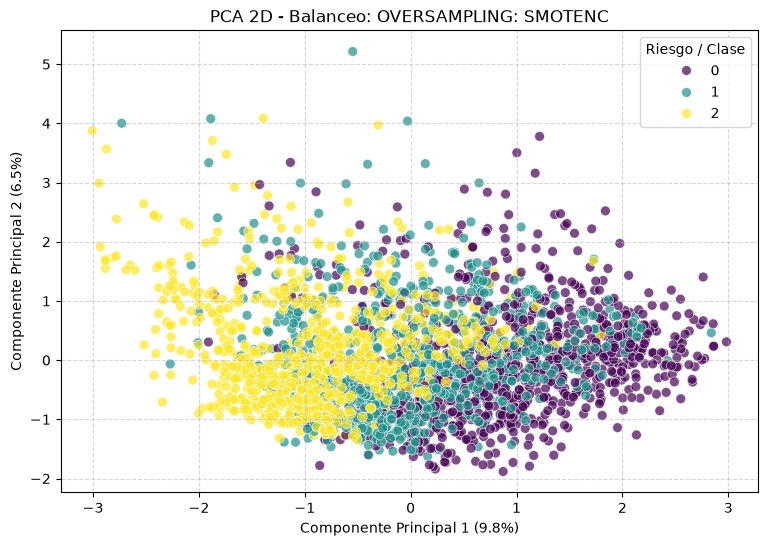

[Oversampling: SMOTENC] Muestras: 2703 | Varianza explicada acumulada (PC1 + PC2): 16.28%



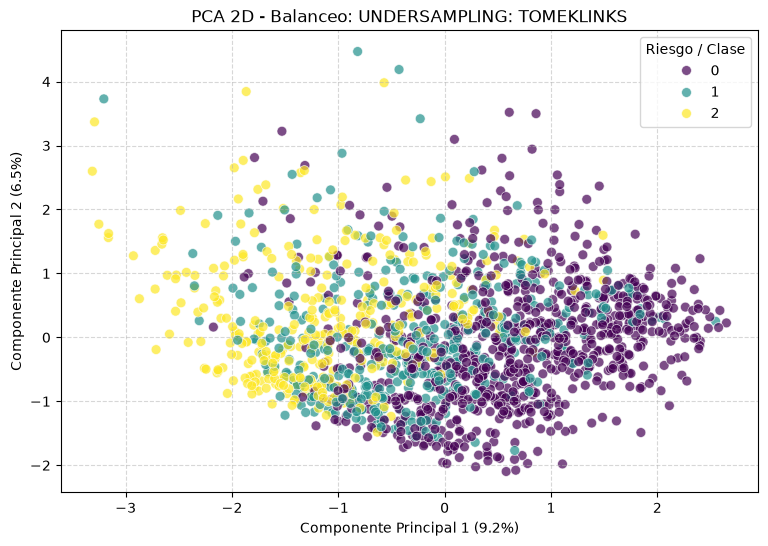

[Undersampling: TomekLinks] Muestras: 1621 | Varianza explicada acumulada (PC1 + PC2): 15.69%



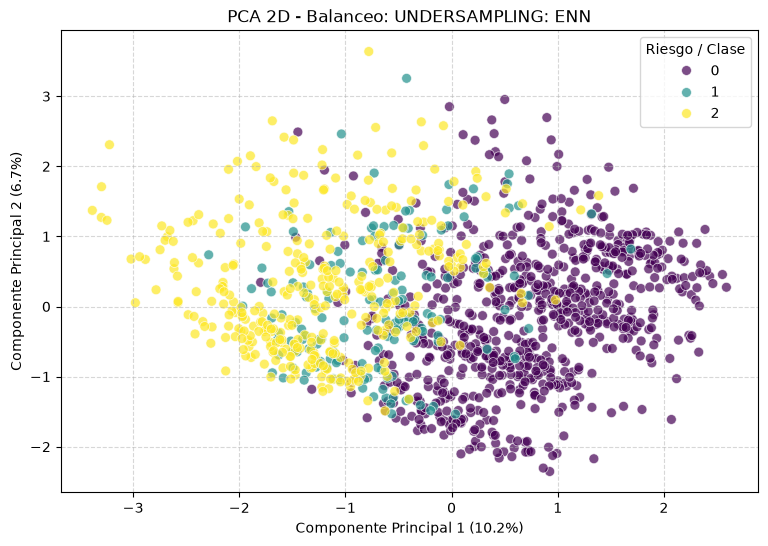

[Undersampling: ENN] Muestras: 1281 | Varianza explicada acumulada (PC1 + PC2): 16.81%



In [6]:
def graficar_pca_2d(metodo_balanceo, titulo):
    if metodo_balanceo is None:
        # Pipeline solo con preprocesado (imputación con mediana + RobustScaler)
        pipeline_temp = mod.crear_pipeline(LinearDiscriminantAnalysis(), balanceo=None)
        X_train_prep = pipeline_temp.named_steps['preprocesado'].fit_transform(X_train, y_train)
        X_res, y_res = X_train_prep, y_train
    else:
        # Pipeline completo con el balanceo correspondiente ("tomek" o "enn")
        pipeline_bal = mod.crear_pipeline(LinearDiscriminantAnalysis(), balanceo=metodo_balanceo)
        pasos_pre = pipeline_bal.named_steps['preprocesado']
        X_train_prep = pasos_pre.fit_transform(X_train, y_train)
        paso_bal = pipeline_bal.named_steps['balanceo']
        X_res, y_res = paso_bal.fit_resample(X_train_prep, y_train)
    
    # Aplicar PCA a 2 dimensiones
    pca = PCA(n_components=2, random_state=cte.semilla)
    X_res_pca = pca.fit_transform(X_res)
    
    # Crear DataFrame
    df_pca = pd.DataFrame(X_res_pca, columns=['PC1', 'PC2'])
    df_pca['Clase'] = y_res.values
    
    # Visualización en 2D
    plt.figure(figsize=(9, 6))
    sns.scatterplot(
        x='PC1', y='PC2', 
        hue='Clase', 
        data=df_pca, 
        palette='viridis', 
        alpha=0.7,
        s=50
    )
    
    plt.title(f"PCA 2D - Balanceo: {titulo.upper()}")
    plt.xlabel(f"Componente Principal 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
    plt.ylabel(f"Componente Principal 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
    plt.legend(title="Riesgo / Clase")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.show()
    
    print(f"[{titulo}] Muestras: {len(X_res)} | Varianza explicada acumulada (PC1 + PC2): {sum(pca.explained_variance_ratio_)*100:.2f}%\n")

# Datos originales (imputados y escalados, sin undersampling) 
graficar_pca_2d(None, "Original (Balanceo=None)")

# Datos originales (imputados y escalados, sin undersampling) 
graficar_pca_2d("smotenc", "Oversampling: SMOTENC")

# Con TomekLinks
graficar_pca_2d("tomek", "Undersampling: TomekLinks")

# Con ENN
graficar_pca_2d("enn", "Undersampling: ENN")

**Conclusión**

- El balanceo no mejora el rendimiento global de forma consistente. Los mejores valores de F1 macro se obtienen sin balanceo (LDA) y en (SVM), mientras que SMOTENC y ENN no aportan mejoras claras.

- Las técnicas de balanceo aumentan el recall de riesgo alto, pero reducen la precisión. Se detectan más pacientes de alto riesgo, aunque a costa de generar más falsas alarmas.

- TomekLinks ofrece el mejor compromiso entre sensibilidad y rendimiento global. Mejora ligeramente el recall manteniendo un F1 macro cercano al de los datos originales.

- ENN resulta demasiado agresivo. Aunque consigue los mayores recalls para la clase de riesgo alto, produce la mayor caída en F1 macro, por lo que no parece adecuado para este conjunto de datos.

- Los resultados sugieren que el principal problema es el solapamiento entre clases más que el desbalance (50%-30%-20%). Como las diferencias de F1 macro entre sin balanceo, SMOTENC y TomekLinks son pequeñas, en los apartados 4, 5 y 6 se analizan LDA y SVM con cada uno (ENN se descarta), y en el 6.7 se elige el balanceo de cada modelo con el criterio del grupo.

***Durante la búsqueda de hiperparámetros algunas configuraciones de SVM, especialmente determinados kernels polinómicos y combinaciones con valores bajos de C, llegaron a ignorar completamente alguna de las clases, generando advertencias de sklearn sobre precisiones indefinidas***

# 4. Modelo sin Balancear (None)

## 4.1. SVM

`kernel`: tipo de frontera de decisión.
- linear: genera una frontera lineal.
- rbf: permite fronteras no lineales mediante funciones gaussianas.
- poly: utiliza transformaciones polinómicas.
- sigmoid: comportamiento similar a una neurona artificial.

`C`: penalización de los errores de clasificación.
- Valores pequeños (0.1) generan fronteras más grandes.
- Valores grandes (10, 100) intentan clasificar correctamente más observaciones y pueden aumentar el sobreajuste.

`gamma`: controla la influencia de cada observación.
- Valores pequeños producen fronteras suaves.
- Valores grandes permiten fronteras más complejas.
- "scale" y "auto" calculan automáticamente el valor a partir de las características del conjunto de datos.

`degree`: grado del polinomio cuando se utiliza kernel="poly".

In [7]:
# La búsqueda óptima se obtuvo con None en el experimento de balanceo

busqueda_svm = busquedas_svm[None]

print("Mejores parámetros:", busqueda_svm.best_params_)

tabla_svm = mod.tabla_resultados(busqueda_svm, "svm")

tabla_svm.round(3).T

Mejores parámetros: {'modelo__C': 0.1, 'modelo__kernel': 'linear'}


modelo,svm
f1_macro_train,0.675
f1_macro_train_std,0.011
f1_macro_val,0.649
f1_macro_val_std,0.029
precision_macro_train,0.683
precision_macro_train_std,0.011
precision_macro_val,0.654
precision_macro_val_std,0.032
recall_macro_train,0.673
recall_macro_train_std,0.01


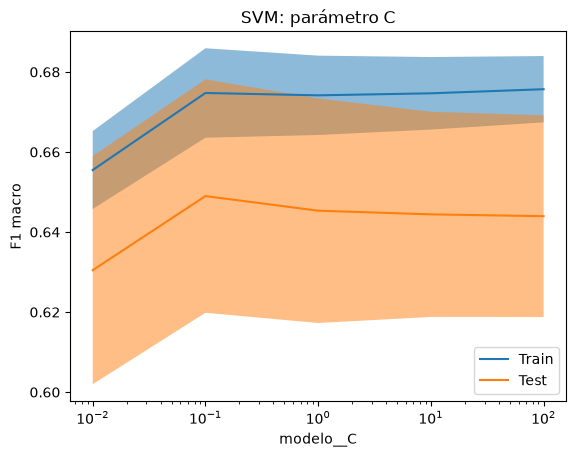

In [8]:
curva_validacion(
    busqueda_svm,
    "modelo__C",
    [0.01, 0.1, 1, 10, 100],
    "SVM: parámetro C"
)

## 4.2. LDA

In [9]:
# LDA sin balanceo

busqueda_lda = busquedas_lda[None]

print("Mejores parámetros:", busqueda_lda.best_params_)

tabla_lda = mod.tabla_resultados(busqueda_lda, "lda")

tabla_lda.round(3).T

Mejores parámetros: {'modelo__shrinkage': 0.1, 'modelo__solver': 'lsqr'}


modelo,lda
f1_macro_train,0.677
f1_macro_train_std,0.01
f1_macro_val,0.66
f1_macro_val_std,0.038
precision_macro_train,0.684
precision_macro_train_std,0.01
precision_macro_val,0.666
precision_macro_val_std,0.042
recall_macro_train,0.675
recall_macro_train_std,0.009


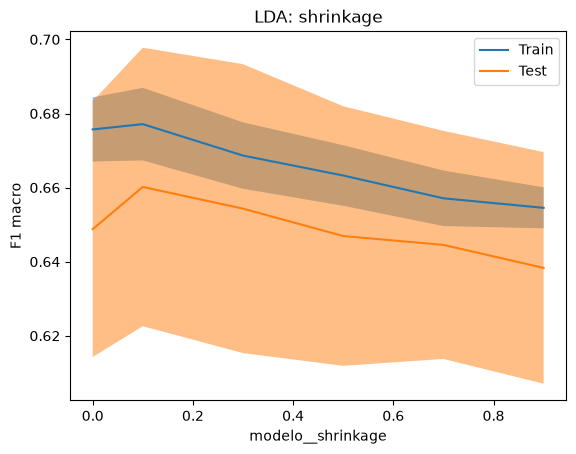

In [10]:
curva_validacion(
    busqueda_lda,
    "modelo__shrinkage",
    [0.0, 0.1, 0.3, 0.5, 0.7, 0.9],
    "LDA: shrinkage"
)

## 4.3. Comparación de modelos

In [11]:
busquedas = {"lda": busqueda_lda,"svm": busqueda_svm,}
comparacion = pd.concat([tabla_lda,tabla_svm,])
display(comparacion[["f1_macro_val","f1_macro_val_std","recall_alto_val","recall_alto_val_std","precision_alto_val","diferencia_train_val"]].sort_values("f1_macro_val",ascending=False).round(3))
print("Mejores hiperparámetros")
display(comparacion[["mejores_parametros"]])

,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,diferencia_train_val
modelo,,,,,,
lda,0.660,0.038,0.681,0.059,0.698,0.017
svm,0.649,0.029,0.676,0.041,0.694,0.026


Mejores hiperparámetros


,mejores_parametros
modelo,
lda,"{'modelo__shrinkage': 0.1, 'modelo__solver': '..."
svm,"{'modelo__C': 0.1, 'modelo__kernel': 'linear'}"


**Conclusión**

- LDA obtiene el mejor rendimiento global. Alcanza un F1 macro de 0,660, ligeramente superior al de SVM (0,649), así como un mejor recall de la clase de riesgo alto (0,681 frente a 0,676) y una mayor precisión (0,698 frente a 0,694).

- Ambos modelos muestran una buena capacidad de generalización. La diferencia entre entrenamiento y validación es muy baja en los dos casos (0,017 en LDA y 0,026 en SVM), lo que indica ausencia de sobreajuste importante y una estimación estable del rendimiento futuro.

- La regularización ligera mejora LDA. La curva de validación muestra que los mejores resultados aparecen para valores bajos de shrinkage (≈ 0,1). A medida que aumenta la regularización, el rendimiento en validación disminuye gradualmente, lo que indica que una simplificación excesiva de la matriz de covarianzas elimina información útil para separar las clases.

- SVM alcanza su mejor rendimiento con un modelo lineal sencillo. La curva de validación muestra que el máximo F1 se obtiene para C=0.1, mientras que aumentar la complejidad del modelo no aporta mejoras. Esto sugiere que las relaciones presentes en los datos son relativamente simples y que una frontera de decisión más compleja no mejora la capacidad predictiva.

- Las diferencias entre ambos modelos son pequeñas. Los valores de F1 macro, recall y precisión son muy similares, por lo que ambos constituyen alternativas válidas para el problema. Sin embargo, LDA obtiene sistemáticamente los mejores resultados y presenta el menor sobreajuste, por lo que se considera la opción más adecuada entre los dos modelos analizados.

## 4.4. Comparación de cada fold

In [12]:
# Extraemos los scores de cada fold directamente desde los resultados de validación cruzada en memoria
folds = pd.DataFrame(
    {
        "lda": [
            busqueda_lda.cv_results_[f"split{k}_test_f1_macro"][
                busqueda_lda.best_index_
            ]
            for k in range(cte.n_folds)
        ],
        "svm": [
            busqueda_svm.cv_results_[f"split{k}_test_f1_macro"][
                busqueda_svm.best_index_
            ]
            for k in range(cte.n_folds)
        ],
    }
)

# Calculamos la diferencia y redondeamos
folds["svm_menos_lda"] = folds["svm"] - folds["lda"]
folds.round(3)

,lda,svm,svm_menos_lda
0,0.683,0.683,0.000
1,0.709,0.678,-0.031
2,0.613,0.622,0.009
3,0.676,0.652,-0.025
4,0.620,0.610,-0.009


## 4.5 Matríz de confusión

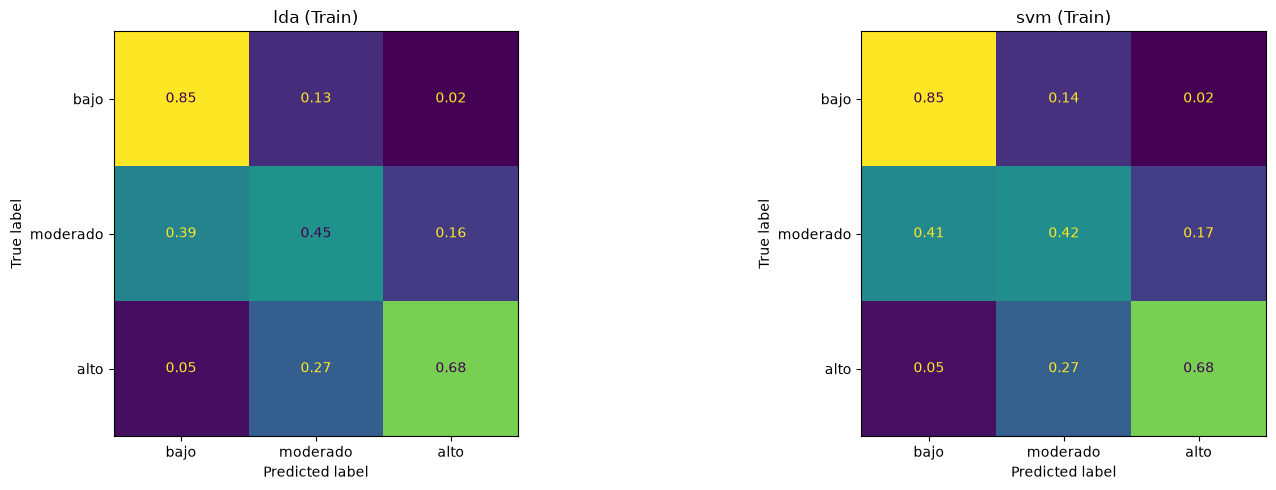

In [13]:

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, (nombre, busqueda) in zip(axes, busquedas.items()):

    y_pred = cross_val_predict(
        busqueda.best_estimator_,
        X_train,
        y_train,
        cv=mod.validador,
        n_jobs=-1
    )

    ConfusionMatrixDisplay.from_predictions(
        y_train,
        y_pred,
        display_labels=["bajo", "moderado", "alto"],
        normalize="true",
        values_format=".2f",
        ax=ax,
        colorbar=False
    )

    ax.set_title(f"{nombre} (Train)")

plt.tight_layout()
plt.show()


## 4.6. **Conclusión**

| | LDA | SVM |
|---|---|---|
| F1 macro (validación) | **0,660 ± 0,038** | 0,649 ± 0,029 |
| Recall de riesgo alto | **0,681** | 0,676 |
| Riesgo alto clasificado como bajo | **0,05** | 0,05 |
| Precisión de riesgo alto | **0,698** | 0,694 |
| Diferencia train-validación | **0,017** | 0,026 |

- **LDA es el mejor modelo según el criterio acordado**, ya que obtiene el mayor F1 macro y también supera ligeramente a SVM en recall y precisión para la clase de riesgo alto.

- **Ambos modelos generalizan bien**, con diferencias train-validación muy reducidas, lo que indica ausencia de sobreajuste relevante.

- **Las diferencias son pequeñas**, por lo que tanto LDA como SVM constituyen alternativas válidas para el problema.

- **Se selecciona LDA como candidato de este notebook debido a los resultados ligeramente superiores, contando con el problema de separación de clases**

# 5. Modelo con oversampling (Smotenc)

## 5.1. SVM

`kernel`: tipo de frontera de decisión.
- linear: genera una frontera lineal.
- rbf: permite fronteras no lineales mediante funciones gaussianas.
- poly: utiliza transformaciones polinómicas.
- sigmoid: comportamiento similar a una neurona artificial.

`C`: penalización de los errores de clasificación.
- Valores pequeños (0.1) generan fronteras más simples.
- Valores grandes (10, 100) intentan clasificar correctamente más observaciones y pueden aumentar el sobreajuste.

`gamma`: controla la influencia de cada observación.
- Valores pequeños producen fronteras suaves.
- Valores grandes permiten fronteras más complejas.
- "scale" y "auto" calculan automáticamente el valor a partir de las características del conjunto de datos.

`degree`: grado del polinomio cuando se utiliza kernel="poly".

In [14]:
busqueda_svm = busquedas_svm["smotenc"]

print("Mejores parámetros:", busqueda_svm.best_params_)

tabla_svm = mod.tabla_resultados(busqueda_svm, "svm")

tabla_svm.round(3).T

Mejores parámetros: {'modelo__C': 1, 'modelo__gamma': 'auto', 'modelo__kernel': 'rbf'}


modelo,svm
f1_macro_train,0.752
f1_macro_train_std,0.007
f1_macro_val,0.636
f1_macro_val_std,0.022
precision_macro_train,0.743
precision_macro_train_std,0.007
precision_macro_val,0.63
precision_macro_val_std,0.023
recall_macro_train,0.765
recall_macro_train_std,0.008


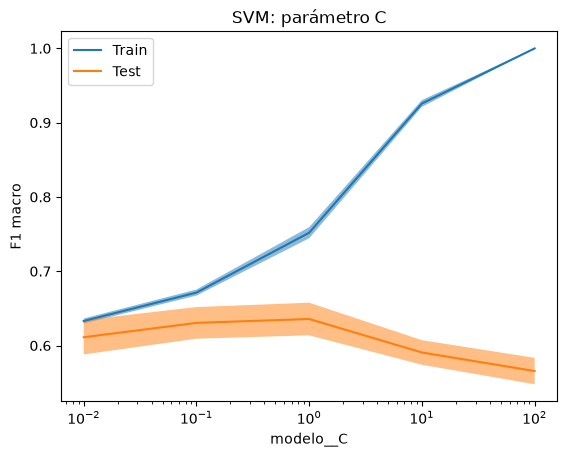

In [15]:
curva_validacion(
    busqueda_svm,
    "modelo__C",
    [0.01, 0.1, 1, 10, 100],
    "SVM: parámetro C"
)

## 5.2. LDA

In [16]:
busqueda_lda = busquedas_lda["smotenc"]

print("Mejores parámetros:", busqueda_lda.best_params_)

tabla_lda = mod.tabla_resultados(busqueda_lda, "lda")

tabla_lda.round(3).T

Mejores parámetros: {'modelo__shrinkage': 0.5, 'modelo__solver': 'lsqr'}


modelo,lda
f1_macro_train,0.658
f1_macro_train_std,0.009
f1_macro_val,0.636
f1_macro_val_std,0.028
precision_macro_train,0.65
precision_macro_train_std,0.009
precision_macro_val,0.629
precision_macro_val_std,0.028
recall_macro_train,0.671
recall_macro_train_std,0.009


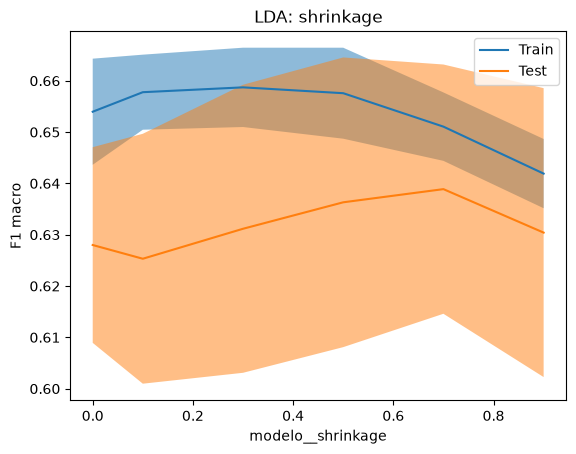

In [17]:
curva_validacion(
    busqueda_lda,
    "modelo__shrinkage",
    [0.0, 0.1, 0.3, 0.5, 0.7, 0.9],
    "LDA: shrinkage"
)

## 5.3. Comparación de modelos

In [18]:
busquedas = {"lda": busqueda_lda,"svm": busqueda_svm,}
comparacion = pd.concat([tabla_lda,tabla_svm,])
display(comparacion[["f1_macro_val","f1_macro_val_std","recall_alto_val","recall_alto_val_std","precision_alto_val","diferencia_train_val"]]
    .sort_values("f1_macro_val",ascending=False).round(3))
print("Mejores hiperparámetros")
display(comparacion[["mejores_parametros"]])


,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,diferencia_train_val
modelo,,,,,,
lda,0.636,0.028,0.759,0.052,0.611,0.021
svm,0.636,0.022,0.726,0.054,0.636,0.116


Mejores hiperparámetros


,mejores_parametros
modelo,
lda,"{'modelo__shrinkage': 0.5, 'modelo__solver': '..."
svm,"{'modelo__C': 1, 'modelo__gamma': 'auto', 'mod..."


**Conclusión**

- Ambos modelos alcanzan el mismo rendimiento global con un **F1 macro de 0,636**.
- LDA generaliza mucho mejor con una diferencia mínima entre entrenamiento y validación (**0,021** frente a **0,116** de SVM, que sufre de *overfitting*).
- LDA logra un mayor *recall* para la clase de riesgo alto (**0,759** vs 0,726), detectando mejor los casos críticos.
- LDA es la mejor opción, ya que ofrece la misma efectividad que SVM pero con mayor estabilidad, menor sobreajuste y mejor detección de los casos de riesgo.

## 5.4. Comparación de cada fold

In [19]:
# Extraemos los scores de cada fold directamente desde los resultados de validación cruzada en memoria
folds = pd.DataFrame(
    {
        "lda": [
            busqueda_lda.cv_results_[f"split{k}_test_f1_macro"][
                busqueda_lda.best_index_
            ]
            for k in range(cte.n_folds)
        ],
        "svm": [
            busqueda_svm.cv_results_[f"split{k}_test_f1_macro"][
                busqueda_svm.best_index_
            ]
            for k in range(cte.n_folds)
        ],
    }
)

# Calculamos la diferencia y redondeamos
folds["svm_menos_lda"] = folds["svm"] - folds["lda"]
folds.round(3)

,lda,svm,svm_menos_lda
0,0.657,0.668,0.011
1,0.669,0.638,-0.032
2,0.599,0.609,0.010
3,0.650,0.649,-0.001
4,0.607,0.615,0.009


## 5.5. Matríz de confusión

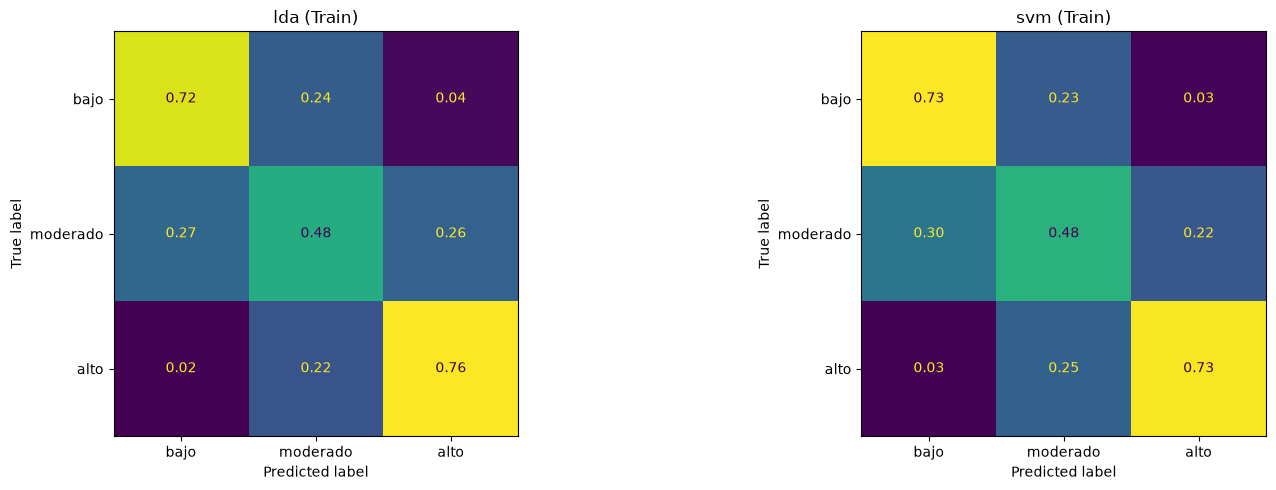

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, (nombre, busqueda) in zip(axes, busquedas.items()):

    y_pred = cross_val_predict(
        busqueda.best_estimator_,
        X_train,
        y_train,
        cv=mod.validador,
        n_jobs=-1
    )

    ConfusionMatrixDisplay.from_predictions(
        y_train,
        y_pred,
        display_labels=["bajo", "moderado", "alto"],
        normalize="true",
        values_format=".2f",
        ax=ax,
        colorbar=False
    )

    ax.set_title(f"{nombre} (Train)")

plt.tight_layout()
plt.show()


## 5.6. **Conclusión**

| Métrica | LDA | SVM |
|---|---:|---:|
| F1 macro (validación) | **0,636 ± 0,028** | **0,636 ± 0,022** |
| Recall de riesgo alto | **0,759 ± 0,052** | 0,726 ± 0,054 |
| Riesgo alto clasificado como bajo | **2 %** | **3 %** |
| Precision de riesgo alto | 0,611 ± 0,049 | **0,636 ± 0,038** |
| Diferencia train-validación | **0,021** | 0,116 |

- **Empate en rendimiento global:** Ambos modelos alcanzan exactamente el mismo F1 macro de validación (**0,636**). Sin embargo, LDA destaca con un mejor *recall* en la clase de riesgo alto (**0,759** frente a 0,726 de SVM), mientras que SVM obtiene una mayor precisión en dicha categoría (**0,636** frente a 0,611).

- **Comportamiento por clases:** Los modelos aciertan fuertemente en el **riesgo bajo** (72 % para LDA y 73 % para SVM) y en el **riesgo alto** (76 % para LDA y 73 % para SVM). Además, el error crítico de clasificar erróneamente un caso de riesgo alto como bajo es muy reducido en ambos casos (**2 %** en LDA y **3 %** en SVM).

- **La principal dificultad:** Ambos modelos muestran su rendimiento más bajo en la categoría intermedia de **riesgo moderado**, acertando exactamente el **48 %** de los casos. El resto se dispersa principalmente entre confusiones hacia el riesgo bajo (27 % en LDA y 30 % en SVM) y hacia el riesgo alto (26 % y 22 %, respectivamente).

- **No se observa un sobreajuste relevante en LDA:** LDA muestra una capacidad de generalización muy superior con una diferencia mínima entre entrenamiento y validación de **0,021**, a diferencia de SVM, que presenta un sobreajuste evidente con una brecha de **0,116**.

- **Se selecciona LDA como candidato:** Se elige **LDA** para continuar el análisis debido a su excelente estabilidad frente al sobreajuste, su mayor sensibilidad (recall) para detectar los casos críticos de riesgo alto y su menor tasa de falsos negativos críticos.

# 6. Modelo con undersampling (Tomeklink)

## 6.1. SVM

`kernel`: tipo de frontera de decisión.
- linear: genera una frontera lineal.
- rbf: permite fronteras no lineales mediante funciones gaussianas.
- poly: utiliza transformaciones polinómicas.
- sigmoid: comportamiento similar a una neurona artificial.

`C`: penalización de los errores de clasificación.
- Valores pequeños (0.1) generan fronteras más simples.
- Valores grandes (10, 100) intentan clasificar correctamente más observaciones y pueden aumentar el sobreajuste.

`gamma`: controla la influencia de cada observación.
- Valores pequeños producen fronteras suaves.
- Valores grandes permiten fronteras más complejas.
- "scale" y "auto" calculan automáticamente el valor a partir de las características del conjunto de datos.

`degree`: grado del polinomio cuando se utiliza kernel="poly".

In [21]:
busqueda_svm = busquedas_svm["tomek"]

print("Mejores parámetros:", busqueda_svm.best_params_)

tabla_svm = mod.tabla_resultados(busqueda_svm, "svm")

tabla_svm.round(3).T

Mejores parámetros: {'modelo__C': 10, 'modelo__gamma': 0.01, 'modelo__kernel': 'rbf'}


modelo,svm
f1_macro_train,0.735
f1_macro_train_std,0.011
f1_macro_val,0.643
f1_macro_val_std,0.024
precision_macro_train,0.746
precision_macro_train_std,0.01
precision_macro_val,0.646
precision_macro_val_std,0.026
recall_macro_train,0.736
recall_macro_train_std,0.011


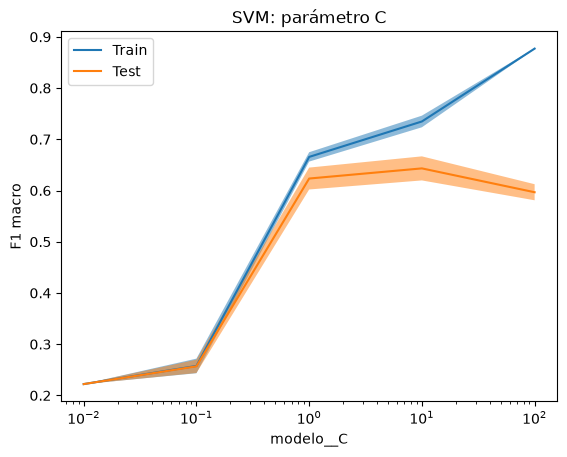

In [22]:
curva_validacion(
    busqueda_svm,
    "modelo__C",
    [0.01, 0.1, 1, 10, 100],
    "SVM: parámetro C"
)

## 6.2. LDA

In [23]:
busqueda_lda = busquedas_lda["tomek"]

print("Mejores parámetros:", busqueda_lda.best_params_)

tabla_lda = mod.tabla_resultados(busqueda_lda, "lda")

tabla_lda.round(3).T

Mejores parámetros: {'modelo__shrinkage': 'auto', 'modelo__solver': 'lsqr'}


modelo,lda
f1_macro_train,0.665
f1_macro_train_std,0.009
f1_macro_val,0.647
f1_macro_val_std,0.04
precision_macro_train,0.671
precision_macro_train_std,0.01
precision_macro_val,0.651
precision_macro_val_std,0.044
recall_macro_train,0.671
recall_macro_train_std,0.009


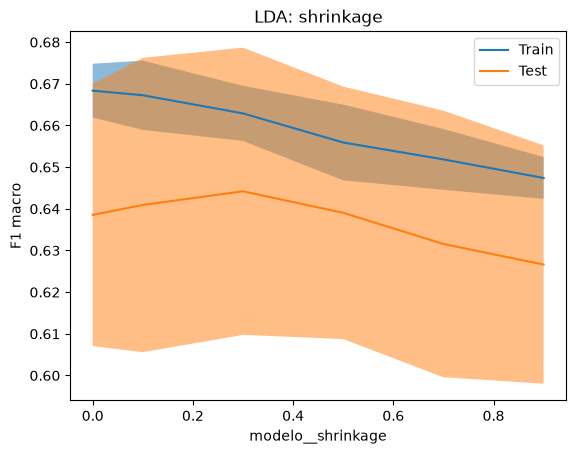

In [24]:
curva_validacion(
    busqueda_lda,
    "modelo__shrinkage",
    [0.0, 0.1, 0.3, 0.5, 0.7, 0.9],
    "LDA: shrinkage"
)

## 6.3. Comparación de modelos

In [25]:
busquedas = {"lda": busqueda_lda,"svm": busqueda_svm,}
comparacion = pd.concat([tabla_lda,tabla_svm,])
display(comparacion[["f1_macro_val","f1_macro_val_std","recall_alto_val","recall_alto_val_std","precision_alto_val","diferencia_train_val"]]
    .sort_values("f1_macro_val",ascending=False).round(3))
print("Mejores hiperparámetros")
display(comparacion[["mejores_parametros"]])


,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,diferencia_train_val
modelo,,,,,,
lda,0.647,0.040,0.717,0.069,0.675,0.019
svm,0.643,0.024,0.698,0.051,0.658,0.092


Mejores hiperparámetros


,mejores_parametros
modelo,
lda,"{'modelo__shrinkage': 'auto', 'modelo__solver'..."
svm,"{'modelo__C': 10, 'modelo__gamma': 0.01, 'mode..."


**Conclusión**

- **Con TomekLinks, LDA y SVM empatan en rendimiento global**: F1 macro de 0,647 ± 0,040 en LDA y 0,643 ± 0,024 en SVM. La diferencia es mucho menor que la variación entre folds.

- **LDA** tiene algo más de recall de riesgo alto (0,717 frente a 0,698) y de precisión de riesgo alto (0,675 frente a 0,658).

- **LDA generaliza mejor**: su diferencia entre entrenamiento y validación es de 0,019, frente a 0,092 en SVM. Con TomekLinks, el mejor SVM usa kernel RBF con C=10, una frontera más flexible que el SVM lineal sin balanceo, y eso se refleja en un sobreajuste mayor.

## 6.4. Comparación de cada fold

In [26]:
folds = pd.DataFrame({
    "lda": [busqueda_lda.cv_results_[f"split{k}_test_f1_macro"][busqueda_lda.best_index_]
            for k in range(cte.n_folds)],
    "svm": [busqueda_svm.cv_results_[f"split{k}_test_f1_macro"][busqueda_svm.best_index_]
            for k in range(cte.n_folds)],
})

folds["svm_menos_lda"] = folds["svm"] - folds["lda"]
folds.round(3)


,lda,svm,svm_menos_lda
0,0.650,0.665,0.015
1,0.704,0.675,-0.028
2,0.600,0.612,0.012
3,0.676,0.637,-0.039
4,0.604,0.627,0.023


## 6.5 Matriz de confusión

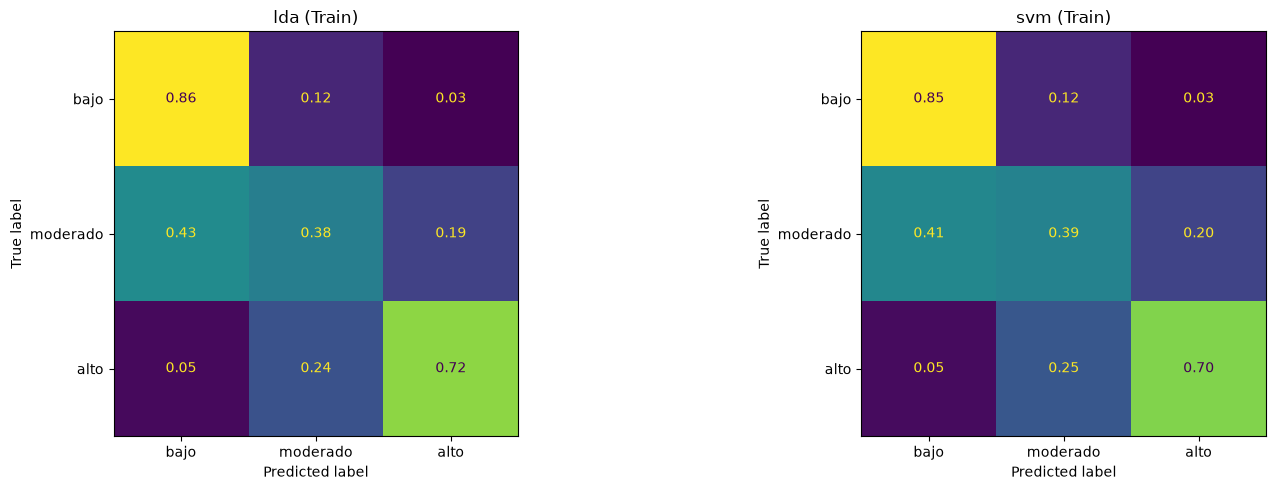

In [27]:

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, (nombre, busqueda) in zip(axes, busquedas.items()):

    y_pred = cross_val_predict(
        busqueda.best_estimator_,
        X_train,
        y_train,
        cv=mod.validador,
        n_jobs=-1
    )

    ConfusionMatrixDisplay.from_predictions(
        y_train,
        y_pred,
        display_labels=["bajo", "moderado", "alto"],
        normalize="true",
        values_format=".2f",
        ax=ax,
        colorbar=False
    )

    ax.set_title(f"{nombre} (Train)")

plt.tight_layout()
plt.show()


## 6.6. **Conclusión**

| Métrica | LDA | SVM |
|---|---:|---:|
| F1 macro (validación) | **0,647 ± 0,040** | 0,643 ± 0,024 |
| Recall de riesgo alto | **0,717 ± 0,069** | 0,698 ± 0,051 |
| Riesgo alto clasificado como bajo | **0,05** | 0,05 |
| Precision de riesgo alto | **0,675 ± 0,058** | 0,658 ± 0,046 |
| Diferencia train-validación | **0,019** | 0,092 |

- **LDA obtiene los mejores resultados globales**, con un F1 macro de 0,647 frente a 0,643 de SVM. También presenta ligeras mejoras en el recall y la precisión de la clase de riesgo alto.

- **Ambos modelos presentan un comportamiento muy similar en la clasificación de las tres clases**. Destacan especialmente en la identificación del riesgo bajo (86 % para LDA y 85 % para SVM) y del riesgo alto (72 % y 70 %, respectivamente).

- **La principal dificultad se encuentra en la clase de riesgo moderado**, donde ambos modelos presentan una capacidad de clasificación considerablemente inferior: únicamente identifican correctamente alrededor del 38-39 % de los casos. Una parte importante de estos se confunde con la clase de riesgo bajo.

- **LDA apenas sobreajusta (0,019); SVM algo más (0,092)**, por la frontera RBF con C=10.

- **Con TomekLinks, LDA queda ligeramente por delante de SVM**, aunque las diferencias son pequeñas y ambos tienen la misma limitación con la clase moderada. El balanceo con el que sigue cada modelo se decide en el 6.7.



## 6.7. Modelo escogido para ensemble

- Se aplica el criterio del grupo dentro de cada modelo:
    - **LDA**: sin balanceo, SMOTENC y TomekLinks empatan en F1 macro (≥ 0,622). En recall de riesgo alto, sin balanceo (0,681) queda por debajo de 0,707, y en errores graves SMOTENC clasifica como bajo a 9 pacientes de riesgo alto frente a 17 con TomekLinks. **Se elige LDA con SMOTENC**.
    - **SVM**: sin balanceo, class_weight, SMOTENC y TomekLinks empatan en F1 macro (≥ 0,620). En recall de riesgo alto, sin balanceo (0,676) queda por debajo de 0,683, y en errores graves class_weight comete 8, SMOTENC 10 y TomekLinks 18. **Se elige SVM con class_weight**, aunque sobreajusta más (0,185 frente a 0,116 de SMOTENC).

- Ahora bien, se debe tener en consideración que riesgo moderado que lo clasifica como alto también es importante por el diagnóstico equivocado de personas que no estan en estado grave, sin embargo, es preferible clasificar alguien que está en mal estado correctamente que alguien que no lo está, ya que es menos sensible en un sentido clínico que el caso de clasificar mal al riesgo alto.

In [28]:
# errores graves (riesgo alto clasificado como bajo) de cada balanceo, con predicciones de validación cruzada
for modelo, busquedas_modelo in {"lda": busquedas_lda, "svm": busquedas_svm}.items():
    for balanceo, busqueda in busquedas_modelo.items():
        y_pred = cross_val_predict(busqueda.best_estimator_, X_train, y_train, cv=mod.validador, n_jobs=-1)
        print(modelo, balanceo, "| alto clasificado como bajo:", ((y_train == 2) & (y_pred == 0)).sum())

# balanceo elegido con el criterio del grupo
busqueda_lda = busquedas_lda["smotenc"]
busqueda_svm = busquedas_svm["class_weight"]
tabla_lda = mod.tabla_resultados(busqueda_lda, "lda")
tabla_svm = mod.tabla_resultados(busqueda_svm, "svm")
mod.guardar_resultados(busqueda_lda, "lda")
mod.guardar_resultados(busqueda_svm, "svm")


lda None | alto clasificado como bajo: 18
lda smotenc | alto clasificado como bajo: 9
lda tomek | alto clasificado como bajo: 17
lda enn | alto clasificado como bajo: 32
svm None | alto clasificado como bajo: 19
svm class_weight | alto clasificado como bajo: 8
svm smotenc | alto clasificado como bajo: 10
svm tomek | alto clasificado como bajo: 18
svm enn | alto clasificado como bajo: 36


# 7. Ensemble

## 7.1 Train Random Forest y Regresión Logística

In [29]:
# Se entrenan primero los modelos de Pablo y Rodrigo nuevamente, para luego combinarlos en un ensemble de votación.

# Random Forest (con los mejores hiperparámetros de Rodrigo)
rejilla_rf = {
    "modelo__n_estimators": [300],
    "modelo__max_depth": [10],
    "modelo__max_features": ["sqrt"],
    "modelo__min_samples_leaf": [1],
}

busqueda_rf = mod.crear_busqueda(
    mod.crear_pipeline(RandomForestClassifier(random_state=cte.semilla), balanceo="class_weight"), 
    rejilla_rf
)
busqueda_rf.fit(X_train, y_train)
tabla_rf = mod.tabla_resultados(busqueda_rf, "random_forest")


# Regresión Logística (con mejores hiperparámetros de Pablo)
rejilla_lr = {
    "modelo__C": [0.1],
    "modelo__l1_ratio": [0],
    "modelo__solver": ["saga"]
}

busqueda_lr = mod.crear_busqueda(
    mod.crear_pipeline(LogisticRegression(random_state=cte.semilla, max_iter=5000), balanceo="class_weight"), 
    rejilla_lr
)
busqueda_lr.fit(X_train, y_train)
tabla_lr = mod.tabla_resultados(busqueda_lr, "logistica")

## 7.2 Voting con mejores hiperparámetros

`voting`: Tipo de votación por mayoría
- **hard**: Votación por mayoría simple basada en las etiquetas discretas predichas por cada modelo. La clase final elegida es la que reciba más votos individuales de los clasificadores.
- **soft**: Votación basada en las probabilidades predichas por cada modelo (promedio ponderado de las probabilidades de cada clase). La clase final es la que obtiene la mayor probabilidad acumulada (requiere que los modelos admitan `predict_proba`).

`weights`: 
- Lista o array de pesos (por ejemplo, `[1, 2, 1, 1]`) que pondera la influencia de cada clasificador individual en la decisión final. Permite otorgar mayor protagonismo o peso en los votos/probabilidades a aquellos modelos que se consideren más fiables o que mejor rendimiento hayan mostrado.

In [30]:
# Traer el svm con probabilidades para poder usarlo en el VotingClassifier
svm_con_probabilidades = clone(busqueda_svm.best_estimator_).set_params(modelo__probability=True, modelo__random_state=cte.semilla)


# Función auxiliar para leer los mejores parámetros guardados previamente
def mejores_parametros(nombre):
    return ast.literal_eval(pd.read_csv(mod.RUTA_RESULTADOS / f"{nombre}.csv")["mejores_parametros"].iloc[0])

# Recrear los modelos directamente con sus mejores parámetros (sin hacer GridSearch otra vez)
rf = mod.crear_pipeline(RandomForestClassifier(random_state=cte.semilla), balanceo="class_weight").set_params(**mejores_parametros("random_forest"))
lr = mod.crear_pipeline(LogisticRegression(solver="saga", max_iter=5000, random_state=cte.semilla), balanceo="class_weight").set_params(**mejores_parametros("logistica"))


# Creamos el VotingClassifier base
voting_clf = VotingClassifier(
    estimators=[
        ('lda', busqueda_lda.best_estimator_),
        ('svm', svm_con_probabilidades),
        ('rf', rf),
        ('lr', lr)
    ]
)

rejilla_voting = {
    "voting": ["hard", "soft"],
    "weights": [[1, 1, 1, 1],  # Pesos iguales
        [3, 1, 1, 1],  # Mayor peso para LDA
        [1, 3, 1, 1],  # Mayor peso para SVM
        [1, 1, 3, 1],  # Mayor peso para Random Forest
        [1, 1, 1, 3],  # Mayor peso para Regresión Logística
        [3, 1, 1, 3]]  # Mayor peso de LDA y LR
}

# Búsqueda y entrenamiento
busqueda_voting = mod.crear_busqueda(voting_clf, rejilla_voting)
busqueda_voting.fit(X_train, y_train)

# Guardar resultados
tabla_voting = mod.tabla_resultados(busqueda_voting, "voting")
mod.guardar_resultados(busqueda_voting, "voting")

display(tabla_voting[["f1_macro_val", "f1_macro_val_std", "recall_alto_val", "recall_alto_val_std", "precision_alto_val", "diferencia_train_val"]].round(3))
print("Mejores parámetros encontrados:", busqueda_voting.best_params_)

c:\Users\pablo\Documents\master_ia_umu\machine_learning\practica\practica1\machine_learning\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,diferencia_train_val
modelo,,,,,,
voting,0.67,0.029,0.753,0.041,0.677,0.246


Mejores parámetros encontrados: {'voting': 'soft', 'weights': [1, 1, 3, 1]}


## 7.3 Comparación de modelos

In [31]:
# Actualizar diccionario de búsquedas
busquedas = {
    "lda": busqueda_lda,
    "svm": busqueda_svm,
    "rf": busqueda_rf,
    "lr": busqueda_lr,
    "voting": busqueda_voting
}

# Actualizar tabla comparativa global
comparacion = pd.concat([tabla_lda, tabla_svm, tabla_rf, tabla_lr, tabla_voting])
display(comparacion[["f1_macro_val", "f1_macro_val_std", "recall_alto_val", "recall_alto_val_std", "precision_alto_val", "diferencia_train_val"]].sort_values("f1_macro_val", ascending=False).round(3))

print("Mejores hiperparámetros:")
display(comparacion[["mejores_parametros"]])

,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,diferencia_train_val
modelo,,,,,,
voting,0.670,0.029,0.753,0.041,0.677,0.246
logistica,0.651,0.034,0.748,0.059,0.631,0.024
random_forest,0.648,0.035,0.723,0.032,0.646,0.348
svm,0.648,0.018,0.728,0.045,0.644,0.185
lda,0.636,0.028,0.759,0.052,0.611,0.021


Mejores hiperparámetros:


,mejores_parametros
modelo,
lda,"{'modelo__shrinkage': 0.5, 'modelo__solver': '..."
svm,"{'modelo__C': 1, 'modelo__gamma': 'scale', 'mo..."
random_forest,"{'modelo__max_depth': 10, 'modelo__max_feature..."
logistica,"{'modelo__C': 0.1, 'modelo__l1_ratio': 0, 'mod..."
voting,"{'voting': 'soft', 'weights': [1, 1, 3, 1]}"


## 7.4 Matríz de confusión

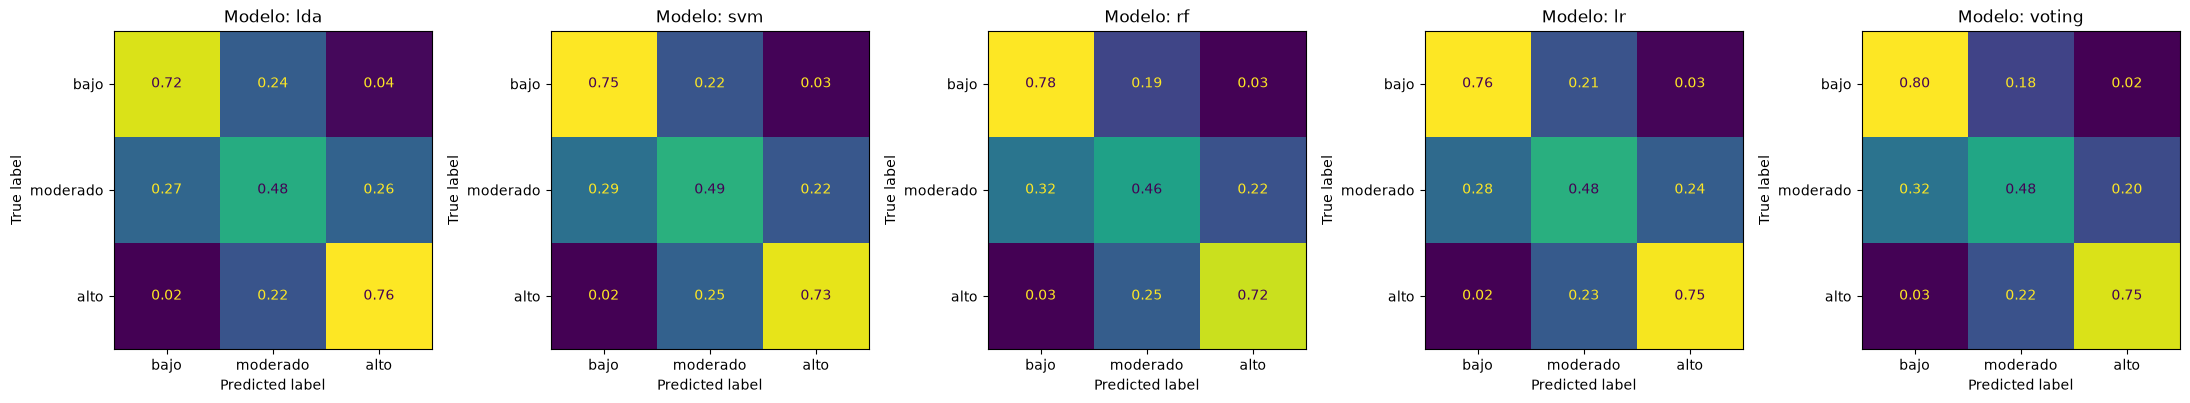

In [32]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))

for ax, (nombre, busqueda) in zip(axes, busquedas.items()):
    y_pred = cross_val_predict(
        busqueda.best_estimator_,
        X_train,
        y_train,
        cv=mod.validador,
        n_jobs=-1
    )

    ConfusionMatrixDisplay.from_predictions(
        y_train,
        y_pred,
        display_labels=["bajo", "moderado", "alto"],
        normalize="true",
        values_format=".2f",
        ax=ax,
        colorbar=False
    )
    ax.set_title(f"Modelo: {nombre}")

plt.tight_layout()
plt.show()

## 7.5. **Conclusión**

| | LDA (SMOTENC) | SVM (class_weight) | Random Forest | Regresión Logística | Voting |
|---|---|---|---|---|---|
| F1 macro (validación) | 0,636 ± 0,028 | 0,648 ± 0,018 | 0,648 ± 0,035 | 0,651 ± 0,034 | **0,670 ± 0,029** |
| Recall de riesgo alto | **0,759** | 0,728 | 0,723 | 0,748 | 0,753 |
| Riesgo alto clasificado como bajo | 9 (2,5 %) | **8 (2,2 %)** | 10 (2,8 %) | **8 (2,2 %)** | 10 (2,8 %) |
| Precisión de riesgo alto | 0,611 | 0,644 | 0,646 | 0,631 | **0,677** |
| Diferencia train-validación | **0,021** | 0,185 | 0,348 | 0,024 | 0,246 |

- **Voting (soft, pesos `[1, 1, 3, 1]`):** combina LDA, SVM, Random Forest y Regresión Logística dando peso triple a Random Forest. Obtiene el mejor F1 macro (**0,670**) y la mejor precisión de riesgo alto (**0,677**), pero hereda buena parte del sobreajuste de Random Forest (**0,246**) y clasifica como bajo a 10 pacientes de riesgo alto, más que la Regresión Logística o el SVM.

- **Regresión Logística:** con un F1 macro de 0,651 y un recall de riesgo alto de 0,748, es junto al SVM el modelo que menos pacientes de riesgo alto clasifica como bajo (8), y apenas sobreajusta (**0,024**).

- **Clase de riesgo moderado:** sigue siendo la difícil para todos los modelos, que solo aciertan entre el 46 % y el 49 % de los casos. El voting acierta el 48 % y confunde el resto sobre todo con riesgo bajo (32 %) y, en menor medida, con alto (20 %).

- **Elección del modelo:** las diferencias de F1 macro entre el voting y los mejores modelos individuales son menores que la variación entre folds. La elección final se hace en `comparacion_final.ipynb`, aplicando el criterio común a los modelos de todo el grupo y con test estadísticos.
